In [17]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
dti = dti[dti.regionname == 'CST_R']
dti = dti[dti.isPatient == 1]



# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0


# Asymmetry index (FA)
ref: Stinear et al., 2019 (https://doi.org/10.1093%2Fbrain%2Fawl333)

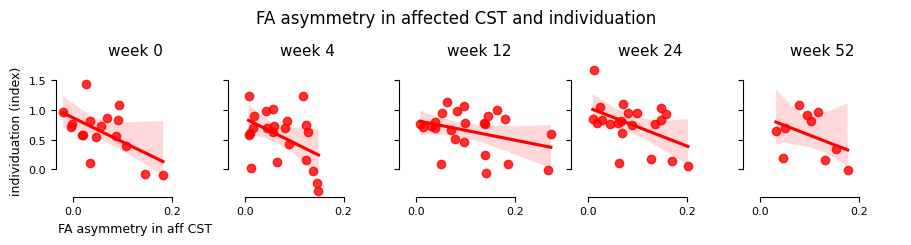

**Pearson R and p-value for FA asymmetry in affected CST and individuation** 

week 0: r = -0.5566862500902164, p-value = 0.02028490001314112
week 4: r = -0.45834809680527144, p-value = 0.03192620306189309
week 12: r = -0.3472900154317531, p-value = 0.09636063169266879
week 24: r = -0.4820391529906481, p-value = 0.02690700584601262
week 52: r = -0.4052980916494655, p-value = 0.24525485622570173


In [18]:
# affected: ipsilesional CST, paretic hand
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    behav_plot = behav[behav.Week == week]
    dti_plot = dti[(dti.Week == week)]
    behav_dti_plot = pd.merge(dti_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_behav'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'indiv_norm', data = behav_dti_plot, ax = ax, color = 'red')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("individuation (index)")
axs[0].set_xlabel(f"FA asymmetry in aff CST")
fig.suptitle(f"FA asymmetry in affected CST and individuation", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA asymmetry in affected CST and individuation** \n")
for week in gl.weeks:
    behav_plot = behav[behav.Week == week]
    dti_plot = dti[(dti.Week == week)]
    behav_dti_plot = pd.merge(dti_plot, behav_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_behav'))

    r_stat, p_stat = stats.pearsonr(behav_dti_plot['asymmetry_index'], behav_dti_plot['indiv_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')


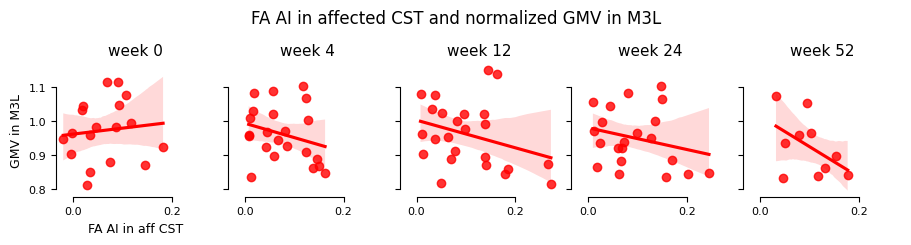

**Pearson R and p-value for MD in affected CST and GMV in M3L (cerebellum)** 

week 0: r = 0.10799671499771049, p-value = 0.669708201751608
week 4: r = -0.27349265879556023, p-value = 0.21811255734735072
week 12: r = -0.3137289290024514, p-value = 0.13546538035797348
week 24: r = -0.25074520341483575, p-value = 0.2729340364628781
week 52: r = -0.48882622360313077, p-value = 0.15165600265379878


In [19]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == 'M3')]
    dti_plot = dti[(dti.Week == week)]
    cerebel_dti_plot = pd.merge(dti_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_cerebel'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'left_norm', data = cerebel_dti_plot, ax = ax, color = 'red')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("GMV in M3L")
axs[0].set_xlabel(f"FA AI in aff CST")
fig.suptitle(f"FA AI in affected CST and normalized GMV in M3L", y = 1.15)


sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for MD in affected CST and GMV in M3L (cerebellum)** \n")
for week in gl.weeks:
    cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == 'M3')]
    dti_plot = dti[(dti.Week == week)]
    cerebel_dti_plot = pd.merge(dti_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_cerebel'))

    r_stat, p_stat = stats.pearsonr(cerebel_dti_plot['asymmetry_index'], cerebel_dti_plot['left_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

These results look like the ones we have with Jing's dataset, just with fewer subjects; not sure why we don't have all dti (images) tho